# Debiased DeBERTa-v3-base: reducing the word-overlap shortcut
Earlier results showed that models trained on QQP learn a shortcut: "if two sentences share most of their words, they are paraphrases". This works on QQP but fails on PAWS, where DeBERTa trained on QQP only reached 0.524 accuracy (below the 0.558 majority guess).

In this notebook we try to reduce that shortcut with example reweighting, a method used in the debiasing literature (Schuster et al., 2019; Utama et al., 2020):
1. Train a bias model that can only see word overlap (our TF-IDF + LR baseline).
2. Give every QQP training pair a weight: small if the bias model already gets it right easily, large if word overlap is misleading.
3. Fine-tune DeBERTa on QQP again with a weighted loss, so it learns more from the pairs that need real understanding.

Everything else is identical to the standard DeBERTa runs (same settings, same 5 seeds, best epoch chosen on QQP dev F1). PAWS is never used for training or model selection, so QQP -> PAWS stays a fair test.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="tqdm")
warnings.filterwarnings("ignore", category=FutureWarning, module="torch.jit")

import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HOME"] = "/scratch/gandhi.gau/hf_cache"
os.environ["HF_HUB_OFFLINE"] = "1"      # use the model we already downloaded

import re, json, glob, shutil
import numpy as np
import pandas as pd
import torch
from scipy.special import softmax
from scipy.sparse import hstack, csr_matrix
from datasets import Dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, set_seed)

/home/gandhi.gau/.conda/envs/my_gpu_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU and precision

In [2]:
# fp16 works on every GPU we might get (H200, A100, V100), so we always use it.
# This keeps all 5 seeds trained the same way even if the jobs land on different GPUs.
PRECISION = "fp16"

print("Training on:", torch.cuda.get_device_name(0))
print("Precision:", PRECISION)

Training on: Tesla V100-SXM2-32GB
Precision: fp16


Paths and settings

In [3]:
MODEL_NAME = "microsoft/deberta-v3-base"
SEEDS = [42, 43, 44, 45, 46]                                   # same seeds as the standard runs
SPLITS = "/home/gandhi.gau/NLP_Project/paraphrase/splits"
OUT = "/scratch/gandhi.gau/paraphrase/out_deberta"             # models and logits
RESULTS = "/home/gandhi.gau/NLP_Project/deberta_results"       # small result files
EXPORT = "/home/gandhi.gau/NLP_Project/deberta_export"         # files for the comparison notebook

for p in (OUT, RESULTS, f"{EXPORT}/preds"):
    os.makedirs(p, exist_ok=True)

Loading the cleaned splits

In [4]:
# same CSVs as every other notebook, so all models see the same data
data = {}
for ds in ["mrpc", "qqp", "paws"]:
    data[ds] = {}
    for split in ["train", "dev", "test"]:
        df = pd.read_csv(f"{SPLITS}/{ds}_{split}.csv", keep_default_na=False)
        df["sentence1"] = df["sentence1"].astype(str)
        df["sentence2"] = df["sentence2"].astype(str)
        data[ds][split] = df

for ds in data:
    print(ds, {split: len(df) for split, df in data[ds].items()})

mrpc {'train': 3301, 'dev': 367, 'test': 408}
qqp {'train': 36000, 'dev': 4000, 'test': 5000}
paws {'train': 49259, 'dev': 7983, 'test': 8000}


Helper Functions (Same as the DeBERTa notebook)

In [5]:
_tok_cache = {}
def get_tok(model_name):
    # load the tokenizer once and reuse it
    if model_name not in _tok_cache:
        _tok_cache[model_name] = AutoTokenizer.from_pretrained(model_name)
    return _tok_cache[model_name]

def build(ds, model_name, max_len=128):
    # turn each split into token ids; pairs longer than 128 tokens are cut
    tok = get_tok(model_name)
    out = {}
    for split in ["train", "dev", "test"]:
        df = data[ds][split][["sentence1", "sentence2", "label"]].reset_index(drop=True)
        d = Dataset.from_pandas(df, preserve_index=False)
        d = d.map(lambda b: tok(b["sentence1"], b["sentence2"], truncation=True, max_length=max_len),
                  batched=True, remove_columns=["sentence1", "sentence2"])
        out[split] = d
    return out

def metrics(p):
    preds = np.argmax(p.predictions, axis=-1)
    y = p.label_ids
    return {"accuracy": accuracy_score(y, preds),
            "precision": precision_score(y, preds, zero_division=0),
            "recall": recall_score(y, preds, zero_division=0),
            "f1": f1_score(y, preds)}

## The bias model
The bias model is our TF-IDF + LR baseline. It only sees word-overlap features (cosine similarity, Jaccard overlap, length difference, and which words appear in one or both sentences), so it cannot use word order or meaning. Whatever it gets right, it gets right through word overlap alone.

In [6]:
# same features as the TF-IDF + LR baseline notebook

# Jaccard overlap = shared words / all unique words in the pair
def jaccard(s1, s2):
    w1 = set(re.findall(r"\w+", s1.lower()))
    w2 = set(re.findall(r"\w+", s2.lower()))
    
    # Avoid division by zero when both sentences are empty
    if len(w1 | w2) == 0:
        return 0.0
    return len(w1 & w2) / len(w1 | w2)

def make_vectorizer(train_df):
    # Single words and word pairs, ignore words seen only once,
    # and use log counts so repeated words don't dominate
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

    # Learn the vocabulary from both columns of the training data only
    all_sentences = pd.concat([train_df["sentence1"], train_df["sentence2"]])
    vec.fit(all_sentences)
    return vec

def build_features(vec, df):
    # Turn each sentence into a TF-IDF vector
    A = vec.transform(df["sentence1"])
    B = vec.transform(df["sentence2"])

    # TF-IDF vectors have length 1, so their dot product is the cosine similarity
    cosine = np.asarray(A.multiply(B).sum(axis=1)).ravel()

    # Jaccard overlap for each pair
    jac = np.array([jaccard(s1, s2) for s1, s2 in zip(df["sentence1"], df["sentence2"])])

    # Difference in number of words, divided by 10 so it's on a similar scale to the others
    len1 = df["sentence1"].str.split().str.len()
    len2 = df["sentence2"].str.split().str.len()
    len_diff = np.abs(len1 - len2).values / 10

    # Put the 3 single-number features side by side
    simple = csr_matrix(np.column_stack([cosine, jac, len_diff]))

    # Word-level features: words in only one sentence, and words in both
    diff = abs(A - B)
    both = A.multiply(B)

    # Join everything into one big sparse matrix (mostly zeros, so this saves memory)
    X = hstack([simple, diff, both]).tocsr()
    return X

## A weight for every QQP training pair
For each training pair, we check how much probability the bias model gives to the correct label, and set the weight to

w = 1 − P_bias(correct label)

- If the bias model is 95% sure of the right answer, the pair gets a weight of 0.05 and hardly counts. The bias model can solve it with shortcuts alone, so it teaches the main model little.
- If the bias model gives the right answer a low probability, the weight is close to 1 and the pair counts fully. These are the pairs the shortcut cannot explain.

If the bias model scored the same pairs it was trained on, it would be overconfident and the weights would be misleading. To avoid this, we use 5-fold cross-validation, so every pair is scored by a model that never saw it during training. As with the baseline, we choose C on the QQP dev set. Finally, we rescale the weights so their average is 1. This keeps the loss on the same scale as normal training.

Computing the weights

In [7]:
BIAS_PATH = f"{RESULTS}/qqp_train_bias_weights.csv"
qqp_train = data["qqp"]["train"].reset_index(drop=True)

if os.path.exists(BIAS_PATH):
    # Weights were saved by an earlier run, so load them.
    bias_df = pd.read_csv(BIAS_PATH)
    print("Loaded saved bias weights")
else:
    # pick C on the QQP dev set, same as in the baseline
    vec = make_vectorizer(qqp_train)
    X_tr = build_features(vec, qqp_train)
    X_dev = build_features(vec, data["qqp"]["dev"])
    best_C, best_f1 = None, -1
    for C in [0.1, 1, 10]:
        lr = LogisticRegression(C=C, solver="liblinear", max_iter=2000).fit(X_tr, qqp_train["label"])
        f1 = f1_score(data["qqp"]["dev"]["label"], lr.predict(X_dev))
        print(f"C={C}: dev F1 = {f1:.3f}")
        if f1 > best_f1:
            best_C, best_f1 = C, f1
    print("Best C:", best_C)

    # score every training pair with 5-fold cross-validation, so each pair is scored by a 
    # bias model that never saw it during training.
    p_correct = np.zeros(len(qqp_train))
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for k, (fit_idx, held_idx) in enumerate(folds.split(qqp_train, qqp_train["label"])):
        fit_df = qqp_train.iloc[fit_idx]
        held_df = qqp_train.iloc[held_idx]

        # Build the vocabulary from this fold's training part only, so no information leaks from the held-out pairs.
        vec = make_vectorizer(fit_df)                    # vocabulary from the training part of this fold only
        lr = LogisticRegression(C=best_C, solver="liblinear", max_iter=2000)
        lr.fit(build_features(vec, fit_df), fit_df["label"])

        # predict_proba returns two probabilities per pair, one per label. Keep the one for the true label.
        probs = lr.predict_proba(build_features(vec, held_df))        # columns: P(label 0), P(label 1)
        labels = held_df["label"].values
        p_correct[held_idx] = probs[np.arange(len(held_df)), labels]   # probability given to the true label
        print(f"fold {k + 1}/5 done")

    # weight = 1 - P(correct), then rescale so the average weight is 1, which keeps the loss on 
    # the same scale as normal training.
    weight = 1 - p_correct
    weight = weight / weight.mean()

    # Save the weights
    bias_df = pd.DataFrame({"p_correct": p_correct, "weight": weight})
    bias_df.to_csv(BIAS_PATH, index=False)

# Checking
print("Bias model accuracy on QQP train (5-fold):", round((bias_df["p_correct"] > 0.5).mean(), 3))
print(bias_df["weight"].describe().round(3))

# Share of pairs that end up with very little influence. This is measured after rescaling.
print("Share of pairs with weight below 0.25:", round((bias_df["weight"] < 0.25).mean(), 3))

C=0.1: dev F1 = 0.535


C=1: dev F1 = 0.638


C=10: dev F1 = 0.678
Best C: 10


fold 1/5 done


fold 2/5 done


fold 3/5 done


fold 4/5 done


fold 5/5 done
Bias model accuracy on QQP train (5-fold): 0.775
count    36000.000
mean         1.000
std          0.940
min          0.000
25%          0.195
50%          0.688
75%          1.624
max          3.491
Name: weight, dtype: float64
Share of pairs with weight below 0.25: 0.29


## Weighted loss
This is the only change to the training method. The normal Trainer averages the cross-entropy loss over all pairs in a batch. In our version, each pair's loss is first multiplied by its weight, so pairs the bias model already finds easy count for less. The dev and test sets have no weights, so they use the normal loss.

Trainer with a weighted loss

In [8]:
# We use Hugging Face's Trainer for the whole training loop (batching, optimizer, evaluation, checkpoints).
# The only thing we want to change is the loss, so we subclass Trainer and override compute_loss.
# Everything else stays exactly the same as normal fine-tuning, so any difference in results comes from the weights.
class WeightedTrainer(Trainer):
    """
    Hugging Face Trainer, but each training pair's loss is multiplied by its bias weight.
    """
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        weights = inputs.get("weight")            # only the training set has weights, so this is None for dev/test

        # the model itself should only get the text inputs
        model_inputs = {k: v for k, v in inputs.items() if k not in ("labels", "weight")}
        outputs = model(**model_inputs)

        # loss of every pair separately (no averaging yet)
        loss_per_pair = torch.nn.functional.cross_entropy(outputs.logits.float(), labels, reduction="none")

        if weights is None:
            loss = loss_per_pair.mean()                        # dev/test: normal loss
        else:
            loss = (loss_per_pair * weights.float()).mean()    # training: weighted loss

        if return_outputs:
            return loss, outputs
        return loss

## Training function
Same settings as the standard DeBERTa runs: learning rate 2e-5, batch size 32, 3 epochs, weight decay 0.01, and the best epoch chosen on QQP dev F1. The differences are the weighted loss and keeping the `weight` column in the training data. Runs that already finished are skipped, so the job can be restarted safely.

In [9]:
def run_debiased(seed, precision="fp16", force=False):
    """
    Fine-tune DeBERTa on QQP with the bias-weighted loss for one seed, then save the best model and its dev scores.
    """
    tag = f"deberta_qqp_s{seed}_debias"
    result_path = f"{OUT}/{tag}_metrics.json"

    # skip runs that already finished
    if os.path.exists(result_path) and not force:
        print("Already done:", tag)
        return json.load(open(result_path))

    set_seed(seed)
    tok = get_tok(MODEL_NAME)
    d = build("qqp", MODEL_NAME)

    # attach the bias weight to each training pair (rows are in the same order as qqp_train)
    assert len(d["train"]) == len(bias_df)
    train_set = d["train"].add_column("weight", bias_df["weight"].astype("float32").tolist())

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    model = model.float()       # DeBERTa-v3 weights are stored in fp16, so we train with fp32 weights

    args = TrainingArguments(
        output_dir=f"{OUT}/{tag}", learning_rate=2e-5,
        per_device_train_batch_size=32, per_device_eval_batch_size=64,
        num_train_epochs=3, weight_decay=0.01, seed=seed,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        save_only_model=True, load_best_model_at_end=True, metric_for_best_model="f1",
        logging_steps=50,
        fp16=(precision == "fp16"), bf16=(precision == "bf16"),
        remove_unused_columns=False,      # otherwise the Trainer drops our "weight" column
        report_to="none")

    trainer = WeightedTrainer(model=model, args=args, train_dataset=train_set, eval_dataset=d["dev"],
                              data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
    trainer.train()

    # dev F1 after each epoch (the best epoch on QQP dev is the one that is kept)
    dev_curve = [{"epoch": h["epoch"], "dev_f1": h["eval_f1"], "dev_loss": h["eval_loss"]}
                 for h in trainer.state.log_history if "eval_f1" in h]

    # save the best model and delete the leftover checkpoints
    trainer.save_model(f"{OUT}/{tag}/best")
    for ck in glob.glob(f"{OUT}/{tag}/checkpoint-*"):
        shutil.rmtree(ck, ignore_errors=True)

    res = {"tag": tag, "seed": seed, "precision": precision, "gpu": torch.cuda.get_device_name(0),
           "best_dev_f1": max(c["dev_f1"] for c in dev_curve), "dev_curve": dev_curve}
    json.dump(res, open(result_path, "w"), indent=2)
    shutil.copy(result_path, RESULTS)

    # free GPU memory before the next run
    del model, trainer
    torch.cuda.empty_cache()

    print(tag, "best dev F1:", round(res["best_dev_f1"], 4))
    return res

## Train the debiased models (QQP, 5 seeds)
We start with seed 42 and check that training went well before running the rest. The dev loss should be a normal number (not NaN), and the dev F1 should be in a sensible range. Once seed 42 passes these checks, we train the remaining four seeds.

In [10]:
# first run doubles as a health check
r = run_debiased(42, precision=PRECISION)

# Print dev F1 and dev loss after each epoch, so we can see training is working.
for c in r["dev_curve"]:
    print("  epoch", c["epoch"], " dev F1 =", round(c["dev_f1"], 4), " dev loss =", round(c["dev_loss"], 4))
    
# Stop here if the dev loss is NaN, because that means training broke.
assert not any(np.isnan(c["dev_loss"]) for c in r["dev_curve"]), "NaN loss: training is broken"

# remaining seeds
for s in SEEDS:
    run_debiased(s, precision=PRECISION)

[transformers] The tokenizer you are loading from 'microsoft/deberta-v3-base' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/36000 [00:00<?, ? examples/s]

Map:   3%|▎         | 1000/36000 [00:00<00:04, 7041.44 examples/s]

Map:   8%|▊         | 3000/36000 [00:00<00:03, 9644.70 examples/s]

Map:  14%|█▍        | 5000/36000 [00:00<00:02, 10404.52 examples/s]

Map:  19%|█▉        | 7000/36000 [00:00<00:02, 10774.02 examples/s]

... (221 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.70s/it]

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.70s/it]

deberta_qqp_s46_debias best dev F1: 0.8308


## Test the debiased models
Each debiased model is tested on all three test sets with no further training. Besides accuracy, F1 and AUC we report:
- **frac_pred_para:** share of pairs the model labels as "paraphrase"
- **specificity:** the share of true non-paraphrases the model labels correctly. This is the most important number on PAWS. A model that relies on word overlap labels most PAWS non-paraphrases as "paraphrase", which gives it low specificity.

Testing on all 3 test sets

In [11]:
# Tokenise the three test sets once, so every seed reuses them.
tok = get_tok(MODEL_NAME)
test_sets = {ds: build(ds, MODEL_NAME)["test"] for ds in ["mrpc", "qqp", "paws"]}

def score(y, logits):
    # all the numbers we report for one model on one test set
    p = np.argmax(logits, -1)   # predicted label = the class with the higher logit
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return {"acc": accuracy_score(y, p), "f1": f1_score(y, p),
            "auc": roc_auc_score(y, softmax(logits, axis=-1)[:, 1]),    
            "frac_pred_para": p.mean(), # share of pairs labelled "paraphrase"
            "specificity": tn / (tn + fp)}  # share of true non-paraphrases labelled correctly

Map:   0%|          | 0/3301 [00:00<?, ? examples/s]

Map:  30%|███       | 1000/3301 [00:00<00:00, 5111.40 examples/s]

Map:  61%|██████    | 2000/3301 [00:00<00:00, 5589.85 examples/s]

Map:  91%|█████████ | 3000/3301 [00:00<00:00, 5763.30 examples/s]

Map: 100%|██████████| 3301/3301 [00:00<00:00, 5639.27 examples/s]

Map:   0%|          | 0/367 [00:00<?, ? examples/s]

... (99 outputs left out)

Map:  75%|███████▌  | 6000/8000 [00:01<00:00, 4954.33 examples/s]

Map:  88%|████████▊ | 7000/8000 [00:01<00:00, 5279.72 examples/s]

Map: 100%|██████████| 8000/8000 [00:01<00:00, 5539.02 examples/s]

Map: 100%|██████████| 8000/8000 [00:01<00:00, 5166.52 examples/s]

In [12]:
rows = []
for s in SEEDS:
    # Load the best checkpoint for this seed
    model = AutoModelForSequenceClassification.from_pretrained(f"{OUT}/deberta_qqp_s{s}_debias/best")
    tester = Trainer(model=model, data_collator=DataCollatorWithPadding(tok),
                     args=TrainingArguments(output_dir=f"{OUT}/tmp", per_device_eval_batch_size=64,
                                            fp16=torch.cuda.is_available(), report_to="none"))
    for test_ds in ["mrpc", "qqp", "paws"]:
        # Get the raw logits and save them
        logits = tester.predict(test_sets[test_ds]).predictions
        np.save(f"{OUT}/deberta_debias_qqp_on_{test_ds}_s{s}_logits.npy", logits)
        y = data[test_ds]["test"]["label"].values
        rows.append({"model": "DeBERTa debiased", "train": "qqp", "test": test_ds, "seed": s, **score(y, logits)})
    
    # Free GPU memory before loading the next seed.
    del model, tester
    torch.cuda.empty_cache()

debias_xfer = pd.DataFrame(rows)
debias_xfer.to_csv(f"{RESULTS}/deberta_debias_transfer_all_runs.csv", index=False)
debias_xfer.groupby("test")[["acc", "f1", "auc", "frac_pred_para", "specificity"]].agg(["mean", "std"]).round(3)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:  32%|███▏      | 65/202 [00:00<00:00, 644.65it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 1026.47it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 3217.63it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:  50%|█████     | 102/202 [00:00<00:00, 1019.65it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 1602.91it/s]

acc            f1           auc        frac_pred_para         \
       mean    std   mean    std   mean    std           mean    std   
test                                                                   
mrpc  0.722  0.015  0.813  0.013  0.713  0.027          0.806  0.031   
paws  0.593  0.036  0.667  0.020  0.712  0.037          0.780  0.040   
qqp   0.870  0.002  0.829  0.005  0.937  0.001          0.393  0.008   

     specificity         
            mean    std  
test                     
mrpc       0.366  0.040  
paws       0.333  0.066  
qqp        0.877  0.005

## Standard vs debiased DeBERTa (both trained on QQP)
We compare the standard and debiased DeBERTa on the same test sets and seeds. If debiasing works, QQP -> QQP should stay about the same, while accuracy and specificity on QQP -> PAWS should improve. We also compare seed by seed. A gain that shows up for every seed is real, while one that only appears for some seeds could be chance.

Comparison

In [13]:
# Load the saved logits of the standard QQP-trained DeBERTa.
def standard_logits(test_ds, s):
    name = f"deberta_xfer_qqp_on_{test_ds}_s{s}_logits.npy"
    if os.path.exists(f"{OUT}/{name}"):
        path = f"{OUT}/{name}"
    else:
        path = f"{RESULTS}/{name}"
    return np.load(path)

# Scoring the standard model with the same score() function that was used for the debiased model.
std_rows = []
for s in SEEDS:
    for test_ds in ["mrpc", "qqp", "paws"]:
        y = data[test_ds]["test"]["label"].values
        logits = standard_logits(test_ds, s)
        row = {"model": "DeBERTa standard", "train": "qqp", "test": test_ds, "seed": s}
        row.update(score(y, logits))
        std_rows.append(row)

std_xfer = pd.DataFrame(std_rows)

# Combine both models into one table and save it.
both = pd.concat([std_xfer, debias_xfer], ignore_index=True)
both.to_csv(f"{RESULTS}/deberta_standard_vs_debiased.csv", index=False)

# Format the 5 seed results as "mean ± std".
def mean_std(x):
    return f"{x.mean():.3f} ± {x.std(ddof=1):.3f}"

# For each metric, show a table with the models as rows and the test sets as columns.
for metric in ["acc", "auc", "specificity"]:
    print(f"\n{metric} (trained on QQP, mean ± std over 5 seeds)")
    summary = both.pivot_table(index="model", columns="test", values=metric, aggfunc=mean_std)
    display(summary)

# Comparing QQP -> PAWS accuracy seed by seed.
paws_only = both[both["test"] == "paws"]
paws_both = paws_only.pivot_table(index="seed", columns="model", values="acc")
paws_both["gain"] = paws_both["DeBERTa debiased"] - paws_both["DeBERTa standard"]

print("\nQQP -> PAWS accuracy per seed:")
display(paws_both.round(3))

avg_gain = paws_both["gain"].mean()
n_improved = (paws_both["gain"] > 0).sum()
print("Average gain:", round(avg_gain, 3), "| seeds that improved:", int(n_improved), "of 5")


acc (trained on QQP, mean ± std over 5 seeds)


test,mrpc,paws,qqp
model,,,
DeBERTa debiased,0.722 ± 0.015,0.593 ± 0.036,0.870 ± 0.002
DeBERTa standard,0.736 ± 0.011,0.524 ± 0.042,0.885 ± 0.002



auc (trained on QQP, mean ± std over 5 seeds)


test,mrpc,paws,qqp
model,,,
DeBERTa debiased,0.713 ± 0.027,0.712 ± 0.037,0.937 ± 0.001
DeBERTa standard,0.750 ± 0.022,0.731 ± 0.053,0.953 ± 0.001



specificity (trained on QQP, mean ± std over 5 seeds)


test,mrpc,paws,qqp
model,,,
DeBERTa debiased,0.366 ± 0.040,0.333 ± 0.066,0.877 ± 0.005
DeBERTa standard,0.381 ± 0.045,0.184 ± 0.084,0.887 ± 0.015



QQP -> PAWS accuracy per seed:


model,DeBERTa debiased,DeBERTa standard,gain
seed,,,
42,0.580,0.460,0.120
43,0.639,0.574,0.065
44,0.542,0.514,0.028
45,0.603,0.544,0.059
46,0.601,0.527,0.074


Average gain: 0.069 | seeds that improved: 5 of 5


## Export
We save the debiased predictions in the same CSV format as the other models, so the comparison notebook can load them directly. In this file, `prob` is P(paraphrase) averaged over the 5 seeds, and `pred` is the predicted label, which is "paraphrase" when that average is above 0.5.

In [14]:
for te in ["mrpc", "qqp", "paws"]:
    df = data[te]["test"][["sentence1", "sentence2", "label"]].copy()

    # P(paraphrase) from each of the 5 seeds
    probs = np.stack([softmax(np.load(f"{OUT}/deberta_debias_qqp_on_{te}_s{s}_logits.npy"), axis=-1)[:, 1]
                      for s in SEEDS])
    df["prob"] = probs.mean(axis=0).round(4)
    df["pred"] = (df["prob"] > 0.5).astype(int)
    for s, p in zip(SEEDS, probs):
        df[f"pred_s{s}"] = (p > 0.5).astype(int)

    df = df[["sentence1", "sentence2", "label", "pred", "prob"] + [f"pred_s{s}" for s in SEEDS]]
    df.to_csv(f"{EXPORT}/preds/deberta_debias_qqp_to_{te}.csv", index=False)

for name in ["deberta_debias_transfer_all_runs.csv", "deberta_standard_vs_debiased.csv", "qqp_train_bias_weights.csv"]:
    shutil.copy(f"{RESULTS}/{name}", EXPORT)
print("Debiased results exported to", EXPORT)

Debiased results exported to /home/gandhi.gau/NLP_Project/deberta_export


## Analysis 

In [15]:
FIG = f"{RESULTS}/figures_debias"
os.makedirs(FIG, exist_ok=True)

# load the saved test logits of one debiased model (one seed) on one test set
def debias_logits(test_ds, seed):
    path = f"{OUT}/deberta_debias_qqp_on_{test_ds}_s{seed}_logits.npy"
    return np.load(path)

# P(paraphrase) for every test pair, averaged over the 5 seeds
def mean_prob(test_ds):
    all_probs = []
    for s in SEEDS:
        logits = debias_logits(test_ds, s)
        prob = softmax(logits, axis=-1)[:, 1]      # column 1 = probability of "paraphrase"
        all_probs.append(prob)
    return np.mean(all_probs, axis=0)

### Dev F1 of each run

In [16]:
rows = []
for s in SEEDS:
    # each run saved its dev scores in a small json file
    res = json.load(open(f"{OUT}/deberta_qqp_s{s}_debias_metrics.json"))

    row = {"seed": s}
    for c in res["dev_curve"]:
        epoch = int(c["epoch"])
        row[f"epoch {epoch}"] = round(c["dev_f1"], 4)
    row["best dev F1"] = round(res["best_dev_f1"], 4)
    row["precision"] = res["precision"]
    row["gpu"] = res["gpu"]
    rows.append(row)

dev_table = pd.DataFrame(rows)
display(dev_table)

# average and spread of the best dev F1 over the 5 seeds
best = dev_table["best dev F1"]
print(f"Best dev F1: {best.mean():.3f} ± {best.std(ddof=1):.3f}")

,seed,epoch 1,epoch 2,epoch 3,best dev F1,precision,gpu
0,42,0.8165,0.8229,0.8268,0.8268,fp16,Tesla V100-SXM2-32GB
1,43,0.7892,0.8376,0.8384,0.8384,fp16,Tesla V100-SXM2-32GB
2,44,0.8143,0.8173,0.8289,0.8289,fp16,Tesla V100-SXM2-32GB
3,45,0.8016,0.8304,0.8406,0.8406,fp16,Tesla V100-SXM2-32GB
4,46,0.7999,0.8243,0.8308,0.8308,fp16,Tesla V100-SXM2-32GB


Best dev F1: 0.833 ± 0.006


## Results Table

In [17]:
rows = []
for test_ds in ["qqp", "paws", "mrpc"]:
    y = data[test_ds]["test"]["label"].values

    # collect each metric for all 5 seeds
    acc, prec, rec, f1, spec = [], [], [], [], []
    for s in SEEDS:
        pred = np.argmax(debias_logits(test_ds, s), axis=-1)
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()

        acc.append(accuracy_score(y, pred))
        prec.append(precision_score(y, pred, zero_division=0))
        rec.append(recall_score(y, pred, zero_division=0))
        f1.append(f1_score(y, pred))
        spec.append(tn / (tn + fp))          # share of real non-paraphrases predicted correctly

    # accuracy of always guessing the most common label
    majority = max(y.mean(), 1 - y.mean())

    row = {"test set": test_ds.upper(), "majority_acc": round(majority, 3)}
    for name, values in [("accuracy", acc), ("precision", prec), ("recall", rec),
                         ("f1", f1), ("specificity", spec)]:
        row[name] = f"{np.mean(values):.3f} ± {np.std(values, ddof=1):.3f}"
    rows.append(row)

results_table = pd.DataFrame(rows)
results_table.to_csv(f"{RESULTS}/deberta_debias_summary.csv", index=False)
results_table

,test set,majority_acc,accuracy,precision,recall,f1,specificity
0,QQP,0.633,0.870 ± 0.002,0.802 ± 0.005,0.859 ± 0.013,0.829 ± 0.005,0.877 ± 0.005
1,PAWS,0.558,0.593 ± 0.036,0.523 ± 0.023,0.922 ± 0.020,0.667 ± 0.020,0.333 ± 0.066
2,MRPC,0.684,0.722 ± 0.015,0.751 ± 0.009,0.886 ± 0.030,0.813 ± 0.013,0.366 ± 0.040


## PAWS accuracy by word overlap

In [18]:
paws_test = data["paws"]["test"].copy()
y_paws = paws_test["label"].values

# True if both sentences use exactly the same words, only in a different order
def same_words(s1, s2):
    words1 = sorted(re.findall(r"\w+", s1.lower()))
    words2 = sorted(re.findall(r"\w+", s2.lower()))
    return words1 == words2

same_list = []
overlap_list = []
for s1, s2 in zip(paws_test["sentence1"], paws_test["sentence2"]):
    same_list.append(same_words(s1, s2))
    overlap_list.append(jaccard(s1, s2))

paws_test["same_words"] = same_list
paws_test["overlap"] = overlap_list

# put the pairs into groups by how much they overlap
paws_test["overlap_group"] = pd.cut(paws_test["overlap"], [0, 0.7, 0.8, 0.9, 0.99, 1.0], include_lowest=True)

# for each pair, how many of the 5 seeds got it right (as a share between 0 and 1)
correct_per_seed = []
for s in SEEDS:
    pred = np.argmax(debias_logits("paws", s), axis=-1)
    correct_per_seed.append(pred == y_paws)
paws_test["debiased_acc"] = np.mean(correct_per_seed, axis=0)

print("Same words in a different order:")
table = paws_test.groupby("same_words").agg(pairs=("label", "size"),
                                            share_paraphrase=("label", "mean"),
                                            debiased_acc=("debiased_acc", "mean"))
display(table.round(3))

print("By word overlap (Jaccard):")
table = paws_test.groupby("overlap_group", observed=True).agg(pairs=("label", "size"),
                                                              share_paraphrase=("label", "mean"),
                                                              debiased_acc=("debiased_acc", "mean"))
display(table.round(3))

Same words in a different order:


,pairs,share_paraphrase,debiased_acc
same_words,,,
False,7147,0.459,0.589
True,853,0.298,0.629


By word overlap (Jaccard):


,pairs,share_paraphrase,debiased_acc
overlap_group,,,
"(-0.001, 0.7]",26,0.077,0.362
"(0.7, 0.8]",545,0.319,0.484
"(0.8, 0.9]",4020,0.470,0.582
"(0.9, 0.99]",1965,0.470,0.611
"(0.99, 1.0]",1444,0.377,0.646


## Confusion matrices

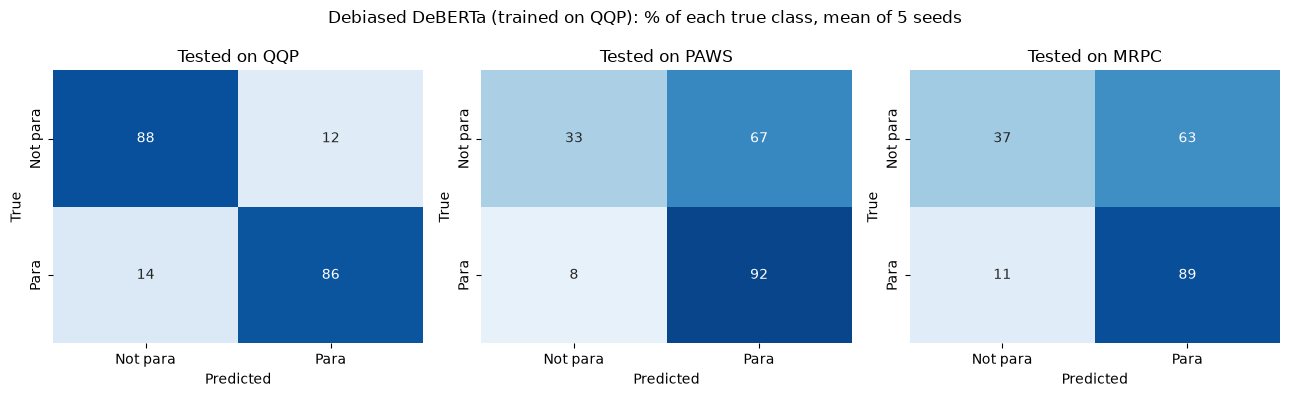

In [19]:
test_names = ["qqp", "paws", "mrpc"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for i in range(len(test_names)):
    test_ds = test_names[i]
    y = data[test_ds]["test"]["label"].values

    # one confusion matrix per seed, as shares of each true class
    matrices = []
    for s in SEEDS:
        pred = np.argmax(debias_logits(test_ds, s), axis=-1)
        matrices.append(confusion_matrix(y, pred, normalize="true"))

    # average over the 5 seeds and turn into percentages
    cm = np.mean(matrices, axis=0) * 100

    sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=axes[i],
                xticklabels=["Not para", "Para"], yticklabels=["Not para", "Para"])
    axes[i].set_title("Tested on " + test_ds.upper())
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("True")

plt.suptitle("Debiased DeBERTa (trained on QQP): % of each true class, mean of 5 seeds")
plt.tight_layout()
plt.savefig(f"{FIG}/1_confusion.png", dpi=200)
plt.show()

## Score distributions

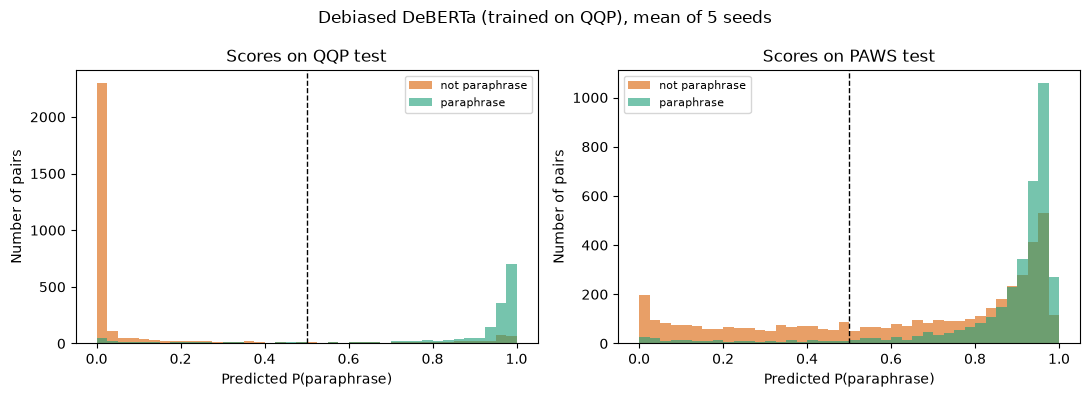

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

plot_sets = ["qqp", "paws"]       # in-domain test and the cross-test
for i in range(len(plot_sets)):
    test_ds = plot_sets[i]
    y = data[test_ds]["test"]["label"].values
    probs = mean_prob(test_ds)

    # one histogram for each true label
    axes[i].hist(probs[y == 0], bins=40, range=(0, 1), alpha=0.6, label="not paraphrase", color="#d95f02")
    axes[i].hist(probs[y == 1], bins=40, range=(0, 1), alpha=0.6, label="paraphrase", color="#1b9e77")

    # dashed line at the 0.5 cut-off
    axes[i].axvline(0.5, color="k", linestyle="--", lw=1)

    axes[i].set_title("Scores on " + test_ds.upper() + " test")
    axes[i].set_xlabel("Predicted P(paraphrase)")
    axes[i].set_ylabel("Number of pairs")
    axes[i].legend(fontsize=8)

plt.suptitle("Debiased DeBERTa (trained on QQP), mean of 5 seeds")
plt.tight_layout()
plt.savefig(f"{FIG}/2_score_hist.png", dpi=200)
plt.show()

## ROC curves

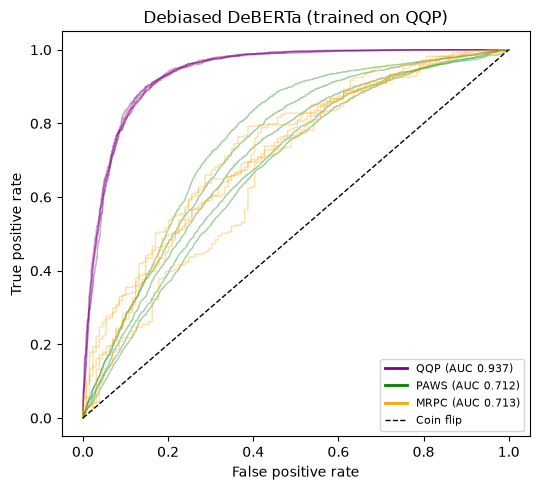

In [21]:
colors = {"qqp": "purple", "paws": "green", "mrpc": "orange"}
fig, ax = plt.subplots(figsize=(5.5, 5))

for test_ds in ["qqp", "paws", "mrpc"]:
    y = data[test_ds]["test"]["label"].values
    aucs = []

    # one curve per seed
    for s in SEEDS:
        prob = softmax(debias_logits(test_ds, s), axis=-1)[:, 1]
        fpr, tpr, _ = roc_curve(y, prob)
        ax.plot(fpr, tpr, color=colors[test_ds], alpha=0.35, lw=1)
        aucs.append(roc_auc_score(y, prob))

    # empty line only used to add one legend entry with the average AUC
    ax.plot([], [], color=colors[test_ds], lw=2, label=f"{test_ds.upper()} (AUC {np.mean(aucs):.3f})")

# the diagonal is what random guessing would give
ax.plot([0, 1], [0, 1], color="black", linestyle="--", lw=1, label="Coin flip")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Debiased DeBERTa (trained on QQP)")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{FIG}/3_roc.png", dpi=200)
plt.show()

## Hand-written test pairs

In [22]:
device = "cuda" if torch.cuda.is_available() else "cpu"
tok = get_tok(MODEL_NAME)

# same 6 pairs as in the BERT and DeBERTa notebooks
pairs = [
    # (sentence1, sentence2, what we expect)
    ("The cat sat on the mat.", "A cat was sitting on the mat.", "paraphrase"),
    ("The dog chased the postman.", "The postman chased the dog.", "NOT (swapped roles)"),
    ("How do I learn Python quickly?", "What is the fastest way to learn Python?", "paraphrase"),
    ("She gave the book to him.", "He gave the book to her.", "NOT (swapped roles)"),
    ("The company reported record profits in 2025.", "The firm posted its highest ever earnings last year.", "paraphrase"),
    ("I love pizza.", "The stock market closed lower today.", "NOT (unrelated)"),
]

# start one table row per pair
rows = []
for s1, s2, expected in pairs:
    rows.append({"s1": s1, "s2": s2, "expected": expected})

# add one column per seed with that model's P(paraphrase)
for s in SEEDS:
    model = AutoModelForSequenceClassification.from_pretrained(f"{OUT}/deberta_qqp_s{s}_debias/best")
    model = model.to(device).eval()

    for i in range(len(pairs)):
        s1, s2, expected = pairs[i]
        enc = tok(s1, s2, return_tensors="pt", truncation=True, max_length=128).to(device)

        # we are only predicting here, so no gradients are needed
        with torch.no_grad():
            logits = model(**enc).logits.float().cpu().numpy()

        prob = softmax(logits, axis=-1)[0, 1]
        rows[i][f"s{s}"] = round(float(prob), 2)

    del model      # free memory before loading the next seed


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 7293.75it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 7376.69it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 9223.87it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 7121.36it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 7358.62it/s]

In [23]:
hand = pd.DataFrame(rows)

# average over the 5 seeds
seed_columns = [f"s{s}" for s in SEEDS]
hand["mean"] = hand[seed_columns].mean(axis=1).round(2)

pd.set_option("display.max_colwidth", 60)
hand

,s1,s2,expected,s42,s43,s44,s45,s46,mean
0,The cat sat on the mat.,A cat was sitting on the mat.,paraphrase,0.95,0.98,0.95,0.98,0.98,0.97
1,The dog chased the postman.,The postman chased the dog.,NOT (swapped roles),0.02,0.11,0.02,0.03,0.04,0.04
2,How do I learn Python quickly?,What is the fastest way to learn Python?,paraphrase,0.97,0.94,0.96,0.98,0.97,0.96
3,She gave the book to him.,He gave the book to her.,NOT (swapped roles),0.00,0.00,0.01,0.00,0.01,0.00
4,The company reported record profits in 2025.,The firm posted its highest ever earnings last year.,paraphrase,0.08,0.01,0.07,0.03,0.03,0.04
5,I love pizza.,The stock market closed lower today.,NOT (unrelated),0.00,0.00,0.00,0.00,0.00,0.00


## Which training pairs got small and large weights

In [24]:
# put the weights next to the training pairs
show = qqp_train.copy()
show["overlap"] = [round(jaccard(s1, s2), 2) for s1, s2 in zip(show["sentence1"], show["sentence2"])]
show["p_correct"] = bias_df["p_correct"].round(3)
show["weight"] = bias_df["weight"].round(3)

pd.set_option("display.max_colwidth", 90)

print("Smallest weights (easy for the bias model):")
display(show.sort_values("weight").head(5))

print("Largest weights (word overlap is misleading here):")
display(show.sort_values("weight", ascending=False).head(5))

# average weight for each label and each overlap group
show["overlap_group"] = pd.cut(show["overlap"], [0, 0.25, 0.5, 0.75, 1.0], include_lowest=True)
avg_weight = show.pivot_table(index="overlap_group", columns="label", values="weight",
                              aggfunc="mean", observed=True)
print("Average weight (rows = word overlap, columns = label):")
display(avg_weight.round(2))

Smallest weights (easy for the bias model):


,sentence1,sentence2,label,overlap,p_correct,weight
30310,"Are designer brands like Gucci, Burberry and Louis Vuitton cheaper in Vietnam than in ...",Arich infotech reviews?,0,0.00,1.0,0.0
8657,My boyfriend told me that he likes another girl and got mad at me when I got upset ove...,"Heartbreak? Heartbreak? She's my girlfriend for two months, I chose her over my girlfr...",0,0.14,1.0,0.0
672,What are comparison shopping engines in Mexico?,How can i start first copy business in indore?,0,0.07,1.0,0.0
5227,What was the worst thing Theodore Roosevelt did?,Will I get Computer Science in Tezpur University in the second round of NE seats couns...,0,0.05,1.0,0.0
17570,What are KPI for insurance intermediaries?,"I got hit by a taxi in Bangalore whose registration number I remember in part, is ther...",0,0.00,1.0,0.0


Largest weights (word overlap is misleading here):


,sentence1,sentence2,label,overlap,p_correct,weight
16117,Whom are the best hair transplantation doctors in hyderbad?,Where do I get hair transplanted in Chennai/Hyderabad. Who is the best doctor?,1,0.21,0.002,3.491
5731,"""Do Australians use the term """"sheila"""" in normal conversation?""","""What does the Australian term """"sheila"""" mean?""",1,0.23,0.002,3.489
2262,How many safety valve in the boiler?,Why are two safety valves provided to boiler?,1,0.15,0.003,3.487
512,What is a ballistic galvanometer?,What is ballistics galvanometer?,1,0.50,0.003,3.486
11236,What is VDerma Revie?,What is VDerma Revi?,1,0.60,0.004,3.484


Average weight (rows = word overlap, columns = label):


label,0,1
overlap_group,,
"(-0.001, 0.25]",0.41,1.59
"(0.25, 0.5]",0.95,1.53
"(0.5, 0.75]",1.42,1.33
"(0.75, 1.0]",1.48,1.00


## Example PAWS pairs

In [25]:
paws_examples = data["paws"]["test"].copy()
paws_examples["prob"] = mean_prob("paws").round(3)

# keep only the real non-paraphrases and sort them by the model's score.
# a low score is correct here, a high score means the model was fooled.
non_para = paws_examples[paws_examples["label"] == 0].sort_values("prob")

share_correct = (non_para["prob"] < 0.5).mean()
print("Share of PAWS non-paraphrases scored below 0.5 (correct):", round(share_correct, 3))
print()

print("Rejected most confidently (correct):")
for i in range(4):
    row = non_para.iloc[i]
    print("  P(paraphrase) =", row["prob"])
    print("  A:", row["sentence1"])
    print("  B:", row["sentence2"])
    print()

print("Still fooled (wrong):")
for i in range(1, 5):
    row = non_para.iloc[-i]
    print("  P(paraphrase) =", row["prob"])
    print("  A:", row["sentence1"])
    print("  B:", row["sentence2"])
    print()

Share of PAWS non-paraphrases scored below 0.5 (correct): 0.336

Rejected most confidently (correct):
  P(paraphrase) = 0.003
  A: His views on the death of Greg Dyke in the radio soap , The Archers , are quoted by Grace Archer in his McTaggart Lecture of 2000 .
  B: His views of the death of Grace Archer in the radio soap , The Archers , are quoted by Greg Dyke in his McTaggart lecture in 2000 .

  P(paraphrase) = 0.003
  A: The Grămești River is a tributary of the Verehia River in Romania .
  B: The Verehia River is a tributary of the River Gramesti in Romania .

  P(paraphrase) = 0.003
  A: The possible values of Î » range from zero to infinity , which corresponds to values of Üü that are greater than the positive number `` L '' / `` m '' .
  B: The possible values of λ range from zero to infinity , which corresponds to values of μ greater than the positive number `` L '' / '' m '' .

  P(paraphrase) = 0.003
  A: She had a son named Harrison and a daughter named Mariah .
  B: He had